# Immuno Compass · Notebook 12: Final figures for the presentation (Day 15)

**Goal:** one clean, consistent set of slide-ready figures (16:9, large text, plain-language titles), saved in
`figures/final/`. Every number is recomputed from the saved results, so the figures always match the notebooks.

| File | Slide message |
|---|---|
| `01_binomial_idea.png` | "15 of 100 patients made ADAs": what one data row means |
| `02_data_pipeline.png` | how 3,334 raw rows became 1,754 cohorts |
| `03_ada_by_origin.png` | the more foreign the protein, the more ADA |
| `04_overdispersion.png` | cohorts vary far more than chance |
| `05_leakage.png` | why we test on unseen molecules |
| `06_model_comparison.png` | no model clearly beats the average for a new molecule |
| `07_coverage.png` | only Beta-Binomial gives honest uncertainty |
| `08_calibration.png` | predictions are over-spread |
| `09_what_drives_ada.png` | factors the methods agree on |
| `10_shap.png`, `11_sequence.png` | copied from notebooks 11 and 09 |

In [ ]:
# ---- Setup: works both in Colab and on a laptop ----
import sys, os
from pathlib import Path

if "google.colab" in sys.modules and not Path("/content/immuno-compass").exists():
    # Download the project. If the repository is private, Colab asks for a GitHub token
    # (github.com/settings/tokens → fine-grained, read access to immuno-compass).
    !git clone -q https://github.com/shibilshamz/immuno-compass.git /content/immuno-compass 2>/dev/null
    if not Path("/content/immuno-compass").exists():
        from getpass import getpass
        token = getpass("GitHub token: ")
        !git clone -q https://{token}@github.com/shibilshamz/immuno-compass.git /content/immuno-compass
        del token
if "google.colab" in sys.modules:
    os.chdir("/content/immuno-compass")
    !pip install -q statsmodels

# Make the shared helper module (src/immuno.py) importable from any folder.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "immuno.py").exists())
sys.path.insert(0, str(ROOT / "src"))
import immuno as im
print("repo root:", ROOT.name)

In [ ]:
import shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.stats import binom
import joblib
warnings.filterwarnings("ignore")
np.random.seed(42)

df = im.load_cohorts(ROOT).join(im.load_folds(ROOT)[["fold_grouped"]])
RES, OUT = ROOT / "results", ROOT / "figures" / "final"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY, INK, INK2, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.figsize": (10, 5.6), "font.size": 13, "axes.titlesize": 17, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "axes.labelsize": 13, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
                     "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight"})
def save(fig, name):
    fig.savefig(OUT / name); plt.show(); print("saved", name)

## 1 · What one row of data means

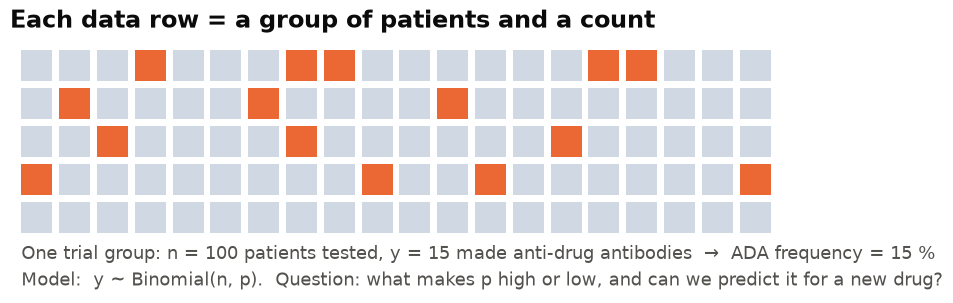

saved 01_binomial_idea.png


In [ ]:
fig, ax = plt.subplots(figsize=(10, 5.6))
rng = np.random.default_rng(3); pos = rng.choice(100, 15, replace=False)
for i in range(100):
    r, c = divmod(i, 20)
    ax.add_patch(Rectangle((c, 4 - r), 0.82, 0.82, color=ORANGE if i in pos else "#cfd8e3", lw=0))
ax.set_xlim(-0.3, 20.2); ax.set_ylim(-1.6, 5.2); ax.set_aspect("equal"); ax.axis("off")
ax.text(0, -0.7, "One trial group: n = 100 patients tested, y = 15 made anti-drug antibodies  →  ADA frequency = 15 %",
        fontsize=13, color=INK2)
ax.text(0, -1.4, "Model:  y ~ Binomial(n, p).  Question: what makes p high or low, and can we predict it for a new drug?",
        fontsize=13, color=INK2)
ax.set_title("Each data row = a group of patients and a count", x=0, y=1.0)
save(fig, "01_binomial_idea.png")

## 2 · Data pipeline

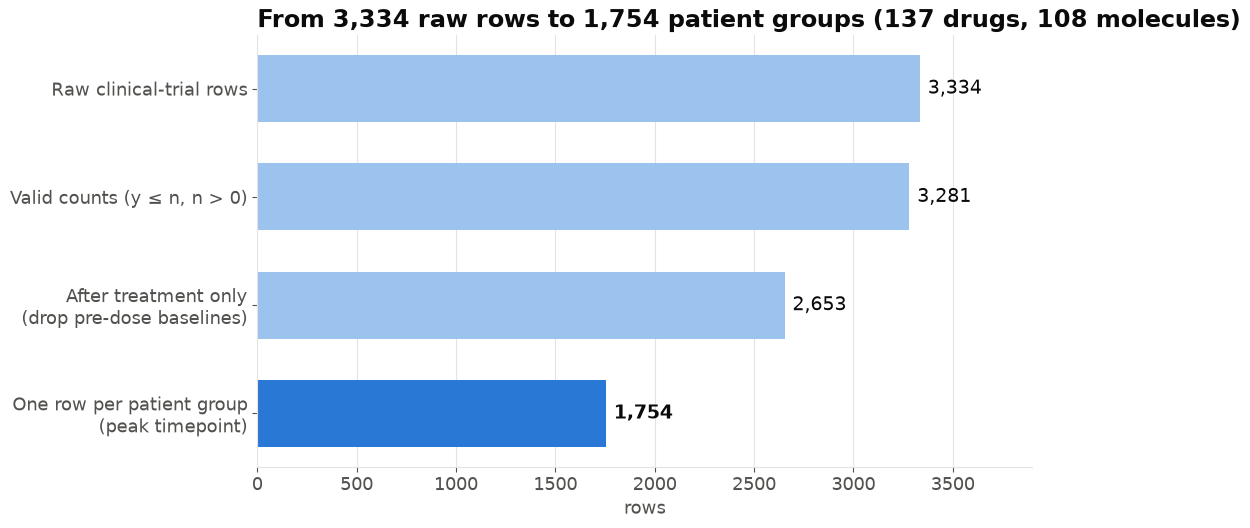

saved 02_data_pipeline.png


In [ ]:
steps = [("Raw clinical-trial rows", 3334), ("Valid counts (y ≤ n, n > 0)", 3281),
         ("After treatment only\n(drop pre-dose baselines)", 2653), ("One row per patient group\n(peak timepoint)", 1754)]
fig, ax = plt.subplots()
for i, (label, v) in enumerate(steps):
    ax.barh(len(steps) - 1 - i, v, color=BLUE if i == len(steps) - 1 else "#9cc2ee", height=0.62)
    ax.text(v + 40, len(steps) - 1 - i, f"{v:,}", va="center", fontsize=14, fontweight="bold" if i == 3 else None)
ax.set_yticks(range(len(steps)), [s[0] for s in steps][::-1]); ax.set_xlim(0, 3900)
ax.set_xlabel("rows"); ax.grid(axis="y", visible=False)
ax.set_title("From 3,334 raw rows to 1,754 patient groups (137 drugs, 108 molecules)")
save(fig, "02_data_pipeline.png")

## 3 · ADA by protein origin (pooled, molecule-bootstrap 95 % interval)

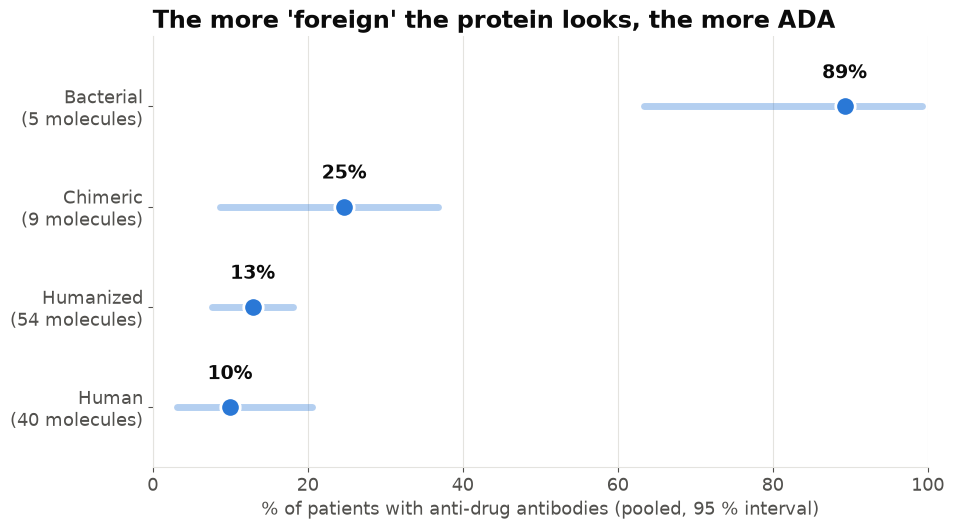

saved 03_ada_by_origin.png


In [ ]:
def boot(g, B=2000, seed=42):
    per = g.groupby(im.GROUP)[["y", "n"]].sum().values
    if len(per) < 2: return np.nan, np.nan
    idx = np.random.default_rng(seed).integers(0, len(per), (B, len(per)))
    return np.percentile(per[idx, 0].sum(1) / per[idx, 1].sum(1), [2.5, 97.5])
order = ["Human", "Humanized", "Chimeric", "Bacterial"]
rows = []
for s in order:
    g = df[df.species == s]; lo, hi = boot(g)
    rows.append((s, g.y.sum() / g.n.sum(), lo, hi, g[im.GROUP].nunique()))
fig, ax = plt.subplots()
for i, (s, p, lo, hi, k) in enumerate(rows):
    ax.plot([lo * 100, hi * 100], [i, i], color=BLUE, lw=5, alpha=0.35, solid_capstyle="round")
    ax.plot(p * 100, i, "o", color=BLUE, ms=14, mec="white", mew=2)
    ax.text(p * 100, i + 0.28, f"{p:.0%}", ha="center", fontsize=14, fontweight="bold")
ax.set_yticks(range(len(rows)), [f"{s}\n({k} molecules)" for s, *_, k in rows]); ax.set_ylim(-0.6, len(rows) - 0.3)
ax.set_xlabel("% of patients with anti-drug antibodies (pooled, 95 % interval)"); ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False)
ax.set_title("The more 'foreign' the protein looks, the more ADA")
save(fig, "03_ada_by_origin.png")

## 4 · Overdispersion

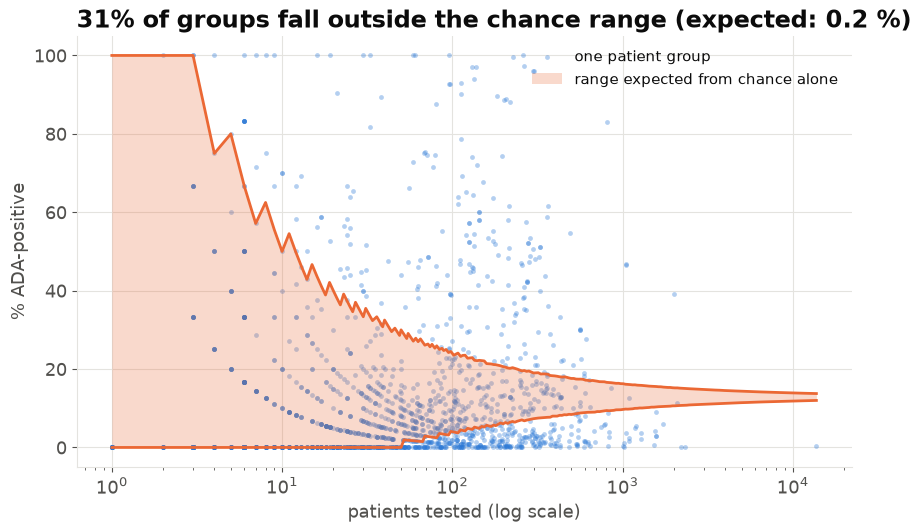

saved 04_overdispersion.png


In [ ]:
overall = df.y.sum() / df.n.sum()
nn = np.unique(np.logspace(0, np.log10(df.n.max()), 300).round().astype(int))
lo, hi = binom.ppf(0.001, nn, overall) / nn, binom.ppf(0.999, nn, overall) / nn
out = ((df.y < binom.ppf(0.001, df.n, overall)) | (df.y > binom.ppf(0.999, df.n, overall))).mean()
fig, ax = plt.subplots()
ax.scatter(df.n, df.ada_freq * 100, s=12, color=BLUE, alpha=0.35, lw=0, label="one patient group")
ax.fill_between(nn, lo * 100, hi * 100, color=ORANGE, alpha=0.25, lw=0, label="range expected from chance alone")
ax.plot(nn, lo * 100, color=ORANGE, lw=2); ax.plot(nn, hi * 100, color=ORANGE, lw=2)
ax.set_xscale("log"); ax.set_xlabel("patients tested (log scale)"); ax.set_ylabel("% ADA-positive")
ax.legend(loc="upper right", fontsize=11)
ax.set_title(f"{out:.0%} of groups fall outside the chance range (expected: 0.2 %)")
save(fig, "04_overdispersion.png")

## 5 · Leakage: random split vs unseen molecules

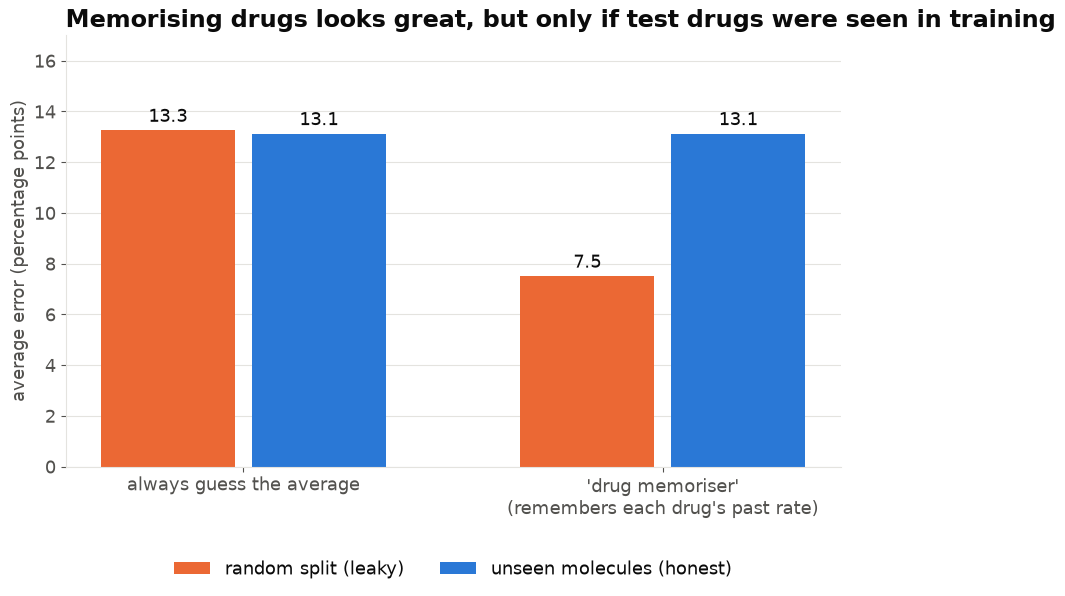

saved 05_leakage.png


In [ ]:
def naive(tr, te): return np.full(len(te), tr.y.sum() / tr.n.sum())
def memo(tr, te):
    r = tr.groupby(im.DRUG)[["y", "n"]].sum(); return te[im.DRUG].map(r.y / r.n).fillna(tr.y.sum() / tr.n.sum()).values
folds = im.load_folds(ROOT); d2 = df.join(folds[["fold_random"]])
vals = {}
for split in ["fold_random", "fold_grouped"]:
    for name, fn in [("naive", naive), ("memo", memo)]:
        vals[(split, name)] = im.cross_validate(d2, split, fn)[0]["wMAE"].mean() * 100
fig, ax = plt.subplots()
x = np.arange(2); w = 0.36
for i, (split, color, label) in enumerate([("fold_random", ORANGE, "random split (leaky)"), ("fold_grouped", BLUE, "unseen molecules (honest)")]):
    v = [vals[(split, "naive")], vals[(split, "memo")]]
    b = ax.bar(x + (i - 0.5) * w, v, w - 0.04, color=color, label=label)
    ax.bar_label(b, fmt="%.1f", fontsize=13, padding=3)
ax.set_xticks(x, ["always guess the average", "'drug memoriser'\n(remembers each drug's past rate)"])
ax.set_ylabel("average error (percentage points)"); ax.grid(axis="x", visible=False); ax.set_ylim(0, 17)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2)
ax.set_title("Memorising drugs looks great, but only if test drugs were seen in training")
save(fig, "05_leakage.png")

## 6 · Model comparison

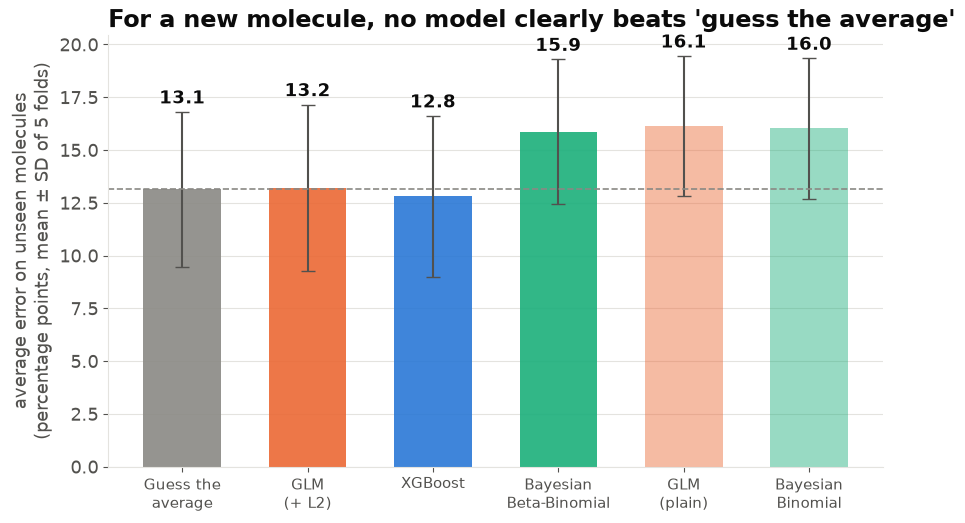

saved 06_model_comparison.png


In [ ]:
MODELS = {"naive": "Guess the\naverage", "glm_l2": "GLM\n(+ L2)", "xgb_default": "XGBoost",
          "bayes_betabinomial": "Bayesian\nBeta-Binomial", "glm_plain": "GLM\n(plain)", "bayes_binomial": "Bayesian\nBinomial"}
cv = pd.concat([pd.read_csv(RES / f"cv_{k}.csv") for k in MODELS])
colors = {"naive": GRAY, "glm_l2": ORANGE, "xgb_default": BLUE, "bayes_betabinomial": AQUA, "glm_plain": ORANGE, "bayes_binomial": AQUA}
fig, ax = plt.subplots()
for i, k in enumerate(MODELS):
    v = cv[cv.model == k]["wMAE"] * 100
    ax.bar(i, v.mean(), 0.62, color=colors[k], alpha=0.45 if k in ("glm_plain", "bayes_binomial") else 0.9)
    ax.errorbar(i, v.mean(), yerr=v.std(), color=INK2, capsize=5, lw=1.5)
    ax.text(i, v.mean() + v.std() + 0.4, f"{v.mean():.1f}", ha="center", fontsize=13, fontweight="bold")
ax.axhline(cv[cv.model == "naive"]["wMAE"].mean() * 100, color=GRAY, ls="--", lw=1.2)
ax.set_xticks(range(len(MODELS)), MODELS.values(), fontsize=11); ax.grid(axis="x", visible=False)
ax.set_ylabel("average error on unseen molecules\n(percentage points, mean ± SD of 5 folds)")
ax.set_title("For a new molecule, no model clearly beats 'guess the average'")
save(fig, "06_model_comparison.png")

## 7 · Honest uncertainty: 90 % interval coverage

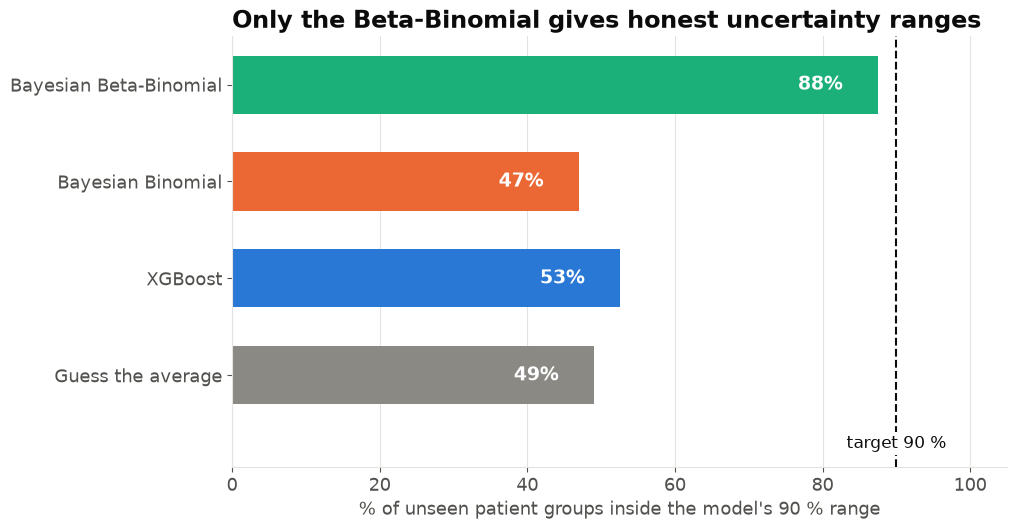

saved 07_coverage.png


In [ ]:
y, n = df.y.values, df.n.values
cov = {}
for k, label in [("naive", "Guess the average"), ("xgb_default", "XGBoost")]:
    p = pd.read_csv(RES / f"oof_{k}.csv").set_index("cohort_id").loc[df.cohort_id, "pred"].values
    lo_, hi_ = im.binomial_interval(n, np.clip(p, 1e-6, 1 - 1e-6)); cov[label] = ((y >= lo_) & (y <= hi_)).mean()
for f, label in [("predictive_bayes_binomial.csv", "Bayesian Binomial"), ("predictive_bayes_betabinomial.csv", "Bayesian Beta-Binomial")]:
    pr = pd.read_csv(RES / f); cov[label] = ((y >= pr.lo.values) & (y <= pr.hi.values)).mean()
fig, ax = plt.subplots()
labels = list(cov); v = [cov[l] * 100 for l in labels]
b = ax.barh(range(len(v)), v, color=[GRAY, BLUE, ORANGE, AQUA], height=0.6)
ax.bar_label(b, fmt="%.0f%%", fontsize=14, padding=-58, color="white", fontweight="bold")
ax.axvline(90, color=INK, ls="--", lw=1.5); ax.text(90, -0.75, "target 90 %", fontsize=12, ha="center", bbox=dict(fc="white", ec="none", pad=2))
ax.set_ylim(-0.95, len(v) - 0.5)
ax.set_yticks(range(len(v)), labels); ax.set_xlim(0, 105); ax.grid(axis="y", visible=False)
ax.set_xlabel("% of unseen patient groups inside the model's 90 % range")
ax.set_title("Only the Beta-Binomial gives honest uncertainty ranges")
save(fig, "07_coverage.png")

## 8 · Calibration

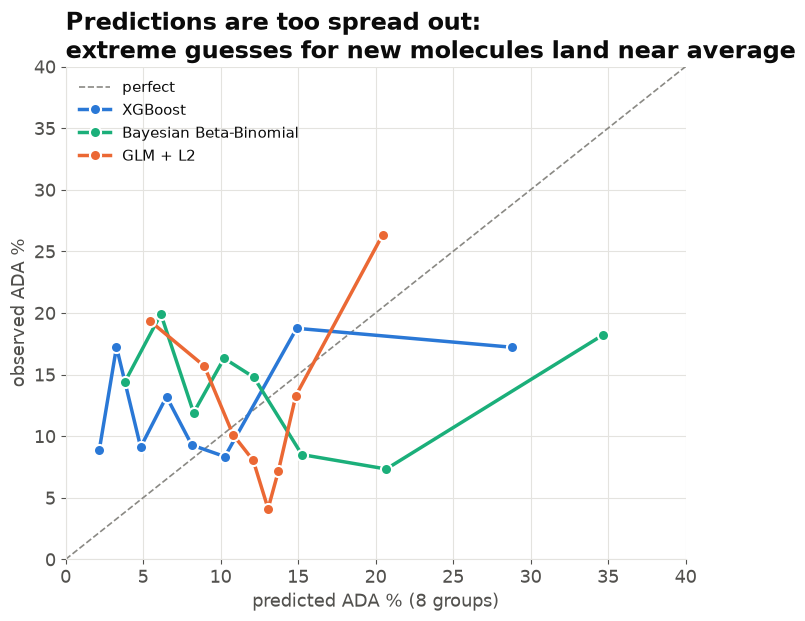

saved 08_calibration.png


In [ ]:
fig, ax = plt.subplots(figsize=(8, 6.4))
ax.plot([0, 40], [0, 40], color=GRAY, ls="--", lw=1.2, label="perfect")
for k, color, label in [("xgb_default", BLUE, "XGBoost"), ("bayes_betabinomial", AQUA, "Bayesian Beta-Binomial"), ("glm_l2", ORANGE, "GLM + L2")]:
    p = pd.read_csv(RES / f"oof_{k}.csv").set_index("cohort_id").loc[df.cohort_id, "pred"].values
    q = pd.qcut(p, 8, labels=False, duplicates="drop")
    t = pd.DataFrame({"q": q, "p": p, "y": y, "n": n}).groupby("q").apply(
        lambda g: pd.Series({"pred": np.average(g.p, weights=g.n), "obs": g.y.sum() / g.n.sum()}), include_groups=False)
    ax.plot(t.pred * 100, t.obs * 100, "-o", color=color, lw=2.5, ms=8, mec="white", mew=1.5, label=label)
ax.set_xlim(0, 40); ax.set_ylim(0, 40)
ax.set_xlabel("predicted ADA % (8 groups)"); ax.set_ylabel("observed ADA %")
ax.legend(loc="upper left", fontsize=11)
ax.set_title("Predictions are too spread out:\nextreme guesses for new molecules land near average")
save(fig, "08_calibration.png")

## 9 · What drives ADA: factors the methods agree on

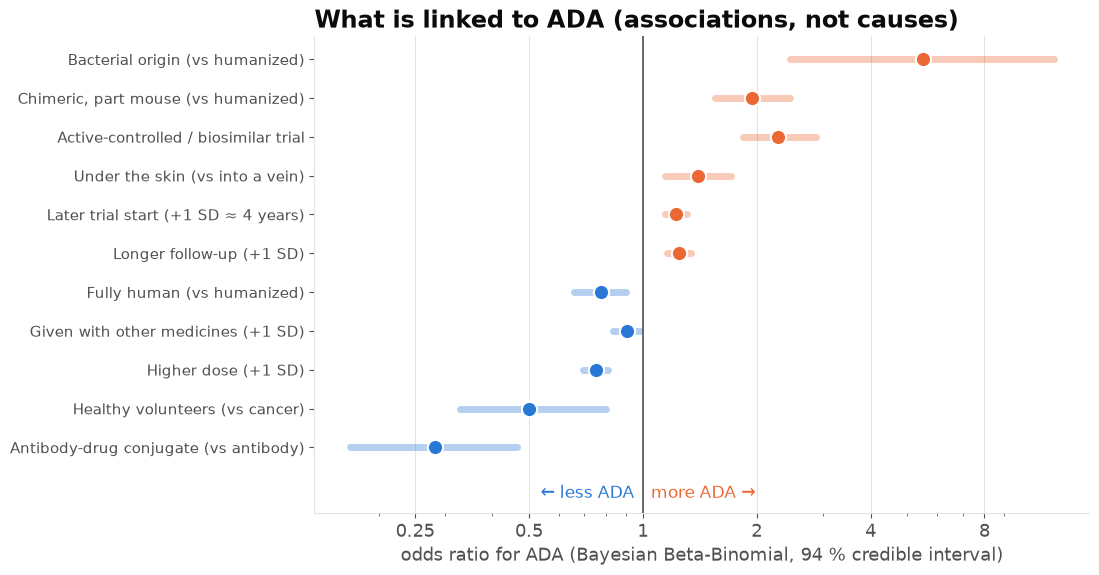

saved 09_what_drives_ada.png


In [ ]:
bb = joblib.load(ROOT / "models" / "bayes_betabinomial.joblib")
cols, beta = bb["columns"], bb["beta"]
KEY = [("species_Bacterial", "Bacterial origin (vs humanized)"), ("species_Chimeric", "Chimeric, part mouse (vs humanized)"),
       ("comparator_Active controls", "Active-controlled / biosimilar trial"), ("route_Subcutaneous", "Under the skin (vs into a vein)"),
       ("start_year", "Later trial start (+1 SD ≈ 4 years)"), ("log_followup_days", "Longer follow-up (+1 SD)"),
       ("species_Human", "Fully human (vs humanized)"), ("co_any_drug", "Given with other medicines (+1 SD)"),
       ("log_dose_mgkg", "Higher dose (+1 SD)"), ("indication_Healthy Volunteer", "Healthy volunteers (vs cancer)"),
       ("modality_Antibody-drug conjugate", "Antibody-drug conjugate (vs antibody)")]
fig, ax = plt.subplots(figsize=(10, 6.2))
for i, (c, label) in enumerate(KEY[::-1]):
    b = beta[:, cols.index(c)]; m, lo, hi = np.exp([b.mean(), np.percentile(b, 3), np.percentile(b, 97)])
    color = ORANGE if m > 1 else BLUE
    ax.plot([lo, hi], [i, i], color=color, lw=5, alpha=0.35, solid_capstyle="round")
    ax.plot(m, i, "o", color=color, ms=11, mec="white", mew=1.5)
ax.axvline(1, color=INK2, lw=1.2); ax.set_xscale("log")
ax.set_xticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
ax.set_yticks(range(len(KEY)), [l for _, l in KEY[::-1]], fontsize=11); ax.grid(axis="y", visible=False)
ax.set_xlabel("odds ratio for ADA (Bayesian Beta-Binomial, 94 % credible interval)")
ax.text(1.05, -1.3, "more ADA →", color=ORANGE, fontsize=12); ax.text(0.95, -1.3, "← less ADA", color=BLUE, fontsize=12, ha="right")
ax.set_ylim(-1.7, len(KEY) - 0.4)
ax.set_title("What is linked to ADA (associations, not causes)")
save(fig, "09_what_drives_ada.png")

## 10 · Copy the SHAP and sequence figures

In [ ]:
for src, dst in [("interp_shap_summary.png", "10_shap.png"), ("seq_go_no_go.png", "11_sequence.png")]:
    shutil.copy(ROOT / "figures" / src, OUT / dst); print("copied", dst)
print(sorted(p.name for p in OUT.glob("*.png")))

copied 10_shap.png
copied 11_sequence.png
['01_binomial_idea.png', '02_data_pipeline.png', '03_ada_by_origin.png', '04_overdispersion.png', '05_leakage.png', '06_model_comparison.png', '07_coverage.png', '08_calibration.png', '09_what_drives_ada.png', '10_shap.png', '11_sequence.png']
